# 09 · Results

Every strategy from notebooks 05–08, on the same test trips, with honest
confidence intervals. How much does each one save, and which differences
are real?

**Key takeaways**
1. **Reinforcement learning is the best strategy.** Starting 30–60 days out,
   it saves **7.5% per trip on average (95% CI 6.6–8.2%)** and **11.3% of
   total spend**, about $16 per trip, losing money on 7% of trips.
2. **It beats LightGBM from every starting point from 21 to 60 days out**,
   and every paired confidence interval excludes zero. The gap is largest
   far from departure (+6.8 points from 60 days out).
3. **From 60 days out it ties the simple "buy 21 days out" rule** (+0.2
   points, CI −1.4 to +1.8). From 45 and 30 days out it beats that rule by
   5–7 points, because blind waiting stops working.
4. **Dynamic programming is the noisiest**: positive only from 60 days out,
   with confidence intervals 3× wider than the others.
5. **Savings depend on the season.** For reinforcement learning, decisions
   made in June saved 13% and those in August–September 2–3%. That's the
   biggest caveat on every number here.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

from flight_pricing.backtest import (START_DAYS, buy_day, decision_date, eligible, fixed_day_rule,
                                     hindsight_best, load_fare_matrix, price_paid)
from flight_pricing.data import DATA_DIR, connect
from flight_pricing.dp import walk_forward_dp
from flight_pricing.features import build_features
from flight_pricing.model import fit_lgb, policy_pct_by_fold, walk_forward
from flight_pricing.plotting import SERIES, TEXT_MUTED, use_style
from flight_pricing.rl import walk_forward_q
from flight_pricing.stats import bootstrap, percentile_ci, savings_stats

use_style()
con = connect()
trips, F = load_fare_matrix(con, full_window_only=False)
route = (trips.origin.astype(str) + "-" + trips.dest.astype(str)).to_numpy()
TEST_MONTHS = pd.period_range("2022-06", "2022-09", freq="M")
(DATA_DIR / "dp").mkdir(exist_ok=True)

## The strategies

All of them are trained walk-forward: each test month uses only trips that
departed before it. All are scored on the same test trips.

| Strategy | From | How it decides |
|---|---|---|
| Buy now | 04 | Always buy on the first day (the baseline, 0% by definition) |
| Buy 21 days out | 05 | Wait until 21 days before departure, whatever the price |
| LightGBM | 06 | Wait while the predicted chance of a 5% drop is above a tuned cutoff |
| Dynamic programming | 07 | Buy when the fare is below the threshold solved from a jump-process price model |
| Reinforcement learning | 08 | Buy when today's fare is no worse than the learned value of waiting |
| Hindsight best | 04 | Buy on the cheapest day. It needs the future, so it's only a ceiling. |

In [2]:
dfs = {h: build_features(con, horizon=h) for h in (7, 14, 21)}
P_lgb, folds_lgb = walk_forward(dfs, trips, F, TEST_MONTHS, fit=fit_lgb)
B_dp = walk_forward_dp(trips, F, TEST_MONTHS, DATA_DIR / "dp")
B_rl = walk_forward_q(dfs[7], trips, F, TEST_MONTHS, objective="price")

def pct_from_buy_matrix(B, idx, s):
    paid = price_paid(F[idx], buy_day(F[idx], B[idx], s))
    return (F[idx, s] - paid) / F[idx, s]

results = []
for s in START_DAYS:
    idx, lgb_pct = policy_pct_by_fold(F, P_lgb, trips, folds_lgb, s, TEST_MONTHS)
    p0 = F[idx, s]
    month = decision_date(trips, s).dt.to_period("M").astype(str).to_numpy()[idx]
    strategies = {
        "Buy 21 days out": pct_from_buy_matrix(fixed_day_rule(F, 21), idx, s) if s > 21 else None,
        "LightGBM": lgb_pct,
        "Dynamic programming": pct_from_buy_matrix(B_dp, idx, s),
        "Reinforcement learning": pct_from_buy_matrix(B_rl, idx, s),
        "Hindsight best": (p0 - hindsight_best(F[idx], s)) / p0,
    }
    for name, pct in strategies.items():
        if pct is not None:
            results.append(pd.DataFrame({"start": s, "strategy": name, "route": route[idx],
                                         "month": month, "start_fare": p0, "pct": pct}))
results = pd.concat(results, ignore_index=True)
results[results.strategy == "LightGBM"].groupby("start").size().rename("test trips").to_frame().T

start,14,21,30,45,60
test trips,26044,24558,21315,17311,10361


## Why a cluster bootstrap?

A confidence interval says how much a number could move with a different
sample of trips. The **bootstrap** estimates that by resampling the data
2,000 times and recomputing the number each time. The middle 95% of the
results is the 95% confidence interval.

Trips on the same route are **not independent**: they share airlines,
competition and demand. Resampling single trips would treat 200 ATL→BOS
trips as 200 independent pieces of evidence, which makes the interval too
narrow. So I resample **whole routes**. Here's the difference for
reinforcement learning:

In [3]:
rows = []
for s in START_DAYS:
    r = results[(results.start == s) & (results.strategy == "Reinforcement learning")]
    fare, pct = r.start_fare.to_numpy(), r.pct.to_numpy()
    clu = percentile_ci(bootstrap(fare, pct, clusters=r.route.to_numpy(), n_boot=2000)).loc["avg_saved_pct"]
    iid = percentile_ci(bootstrap(fare, pct, n_boot=1000)).loc["avg_saved_pct"]
    rows.append({"start": f"{s}d", "estimate": pct.mean(), "cluster CI": f"{clu.low:.3f} to {clu.high:.3f}",
                 "ordinary CI": f"{iid.low:.3f} to {iid.high:.3f}",
                 "width ratio": (clu.high - clu.low) / (iid.high - iid.low)})
pd.DataFrame(rows).round(3)

,start,estimate,cluster CI,ordinary CI,width ratio
0,60d,0.098,0.089 to 0.106,0.094 to 0.101,2.188
1,45d,0.076,0.067 to 0.084,0.073 to 0.079,2.716
2,30d,0.062,0.053 to 0.071,0.060 to 0.065,3.379
3,21d,0.034,0.025 to 0.042,0.031 to 0.036,3.464
4,14d,0.005,-0.002 to 0.010,0.003 to 0.007,3.110


The route-clustered intervals are **2.2–3.5× wider** than the ordinary
ones. The estimates don't change, only the honesty about how precisely I
know them. All intervals below are clustered by route.

## Savings by strategy, with 95% confidence intervals

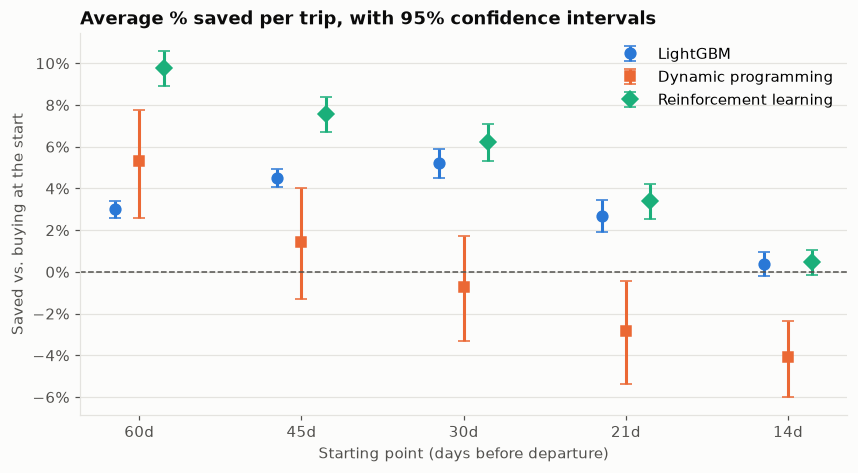

start,60,45,30,21,14
strategy,,,,,
Buy 21 days out,0.096,0.021,-0.009,NaN,NaN
LightGBM,"0.030 (0.026, 0.034)","0.045 (0.041, 0.049)","0.052 (0.045, 0.059)","0.027 (0.019, 0.035)","0.004 (-0.002, 0.010)"
Dynamic programming,"0.053 (0.026, 0.078)","0.014 (-0.013, 0.040)","-0.007 (-0.033, 0.017)","-0.028 (-0.054, -0.004)","-0.041 (-0.060, -0.024)"
Reinforcement learning,"0.098 (0.089, 0.106)","0.076 (0.067, 0.084)","0.062 (0.053, 0.071)","0.034 (0.025, 0.042)","0.005 (-0.002, 0.010)"
Hindsight best,0.303,0.230,0.180,0.136,0.083


In [4]:
models = ["LightGBM", "Dynamic programming", "Reinforcement learning"]
rows = []
for (s, name), r in results.groupby(["start", "strategy"], sort=False):
    fare, pct = r.start_fare.to_numpy(), r.pct.to_numpy()
    point = savings_stats(fare, pct)
    ci = (percentile_ci(bootstrap(fare, pct, clusters=r.route.to_numpy(), n_boot=2000))
          if name in models else None)
    for metric, value in point.items():
        rows.append({"start": s, "strategy": name, "metric": metric, "estimate": value,
                     "low": ci.loc[metric, "low"] if ci is not None else np.nan,
                     "high": ci.loc[metric, "high"] if ci is not None else np.nan})
table = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4.5))
for k, (name, color, marker) in enumerate(zip(models, SERIES, ["o", "s", "D"])):
    d = table[(table.strategy == name) & (table.metric == "avg_saved_pct")].reset_index(drop=True)
    x = np.arange(len(d)) + (k - 1) * 0.15
    ax.errorbar(x, d.estimate, yerr=[d.estimate - d.low, d.high - d.estimate], fmt=marker,
                color=color, markersize=7, capsize=4, linewidth=2, label=name)
ax.axhline(0, color=TEXT_MUTED, linewidth=1, linestyle="--")
ax.set_xticks(range(len(START_DAYS)), [f"{s}d" for s in START_DAYS])
ax.set_title("Average % saved per trip, with 95% confidence intervals")
ax.set_xlabel("Starting point (days before departure)")
ax.set_ylabel("Saved vs. buying at the start")
ax.yaxis.set_major_locator(mticker.MultipleLocator(0.02))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax.legend(loc="upper right")
plt.show()

def fmt(row):
    if np.isnan(row.low):
        return f"{row.estimate:.3f}"
    return f"{row.estimate:.3f} ({row.low:.3f}, {row.high:.3f})"

avg = table[table.metric == "avg_saved_pct"].assign(cell=lambda t: t.apply(fmt, axis=1))
avg.pivot(index="strategy", columns="start", values="cell").reindex(
    ["Buy 21 days out"] + models + ["Hindsight best"])[START_DAYS]

Each cell is the average % saved per trip, with its 95% confidence interval
in parentheses.

- **Reinforcement learning is highest at every starting point.** It's
  clearly above zero from 21 to 60 days out, and from 14 days out nothing
  saves much.
- **LightGBM** is solid from 21 to 45 days out but weak from 60, where it
  buys too early.
- **Dynamic programming** only helps from 60 days out, and its intervals are
  wide: its price model fits some months much better than others.
- **Buy 21 days out** works from 60 days out (9.6%) and fails from closer
  in. It has no interval because it has nothing to learn (and its 21 was
  suggested by this same data).
- **The hindsight best** (10–30%) is the ceiling no real strategy can reach.

## Headline: pooled over starting points 30–60 days out

In [5]:
rows = []
for name in models:
    r = results[(results.strategy == name) & results.start.isin([30, 45, 60])]
    fare, pct = r.start_fare.to_numpy(), r.pct.to_numpy()
    ci = percentile_ci(bootstrap(fare, pct, clusters=r.route.to_numpy(), n_boot=2000))
    point = savings_stats(fare, pct)
    for metric in point.index:
        rows.append({"strategy": name, "metric": metric, "estimate": point[metric],
                     "low": ci.loc[metric, "low"], "high": ci.loc[metric, "high"]})
pooled = pd.DataFrame(rows)
pooled.pivot(index="metric", columns="strategy", values="estimate").round(3)

strategy,Dynamic programming,LightGBM,Reinforcement learning
metric,,,
avg_saved_pct,0.013,0.045,0.075
avg_saved_usd,9.218,9.353,15.655
share_lost_money,0.098,0.043,0.070
total_saved_pct,0.066,0.067,0.113


In [6]:
pooled[pooled.metric.isin(["avg_saved_pct", "total_saved_pct"])].round(4)

,strategy,metric,estimate,low,high
0,LightGBM,avg_saved_pct,0.0450,0.0406,0.0494
1,LightGBM,total_saved_pct,0.0674,0.0618,0.0729
4,Dynamic programming,avg_saved_pct,0.0132,-0.0131,0.0378
5,Dynamic programming,total_saved_pct,0.0664,0.0452,0.0861
8,Reinforcement learning,avg_saved_pct,0.0746,0.0660,0.0821
9,Reinforcement learning,total_saved_pct,0.1128,0.1044,0.1208


Pooling every test decision made 30–60 days out:

| | LightGBM | Dynamic programming | **Reinforcement learning** |
|---|---|---|---|
| Average % saved per trip | 4.5% (4.1–4.9) | 1.3% (−1.3–3.8) | **7.5% (6.6–8.2)** |
| % of total spend saved | 6.7% (6.2–7.3) | 6.6% (4.5–8.6) | **11.3% (10.4–12.1)** |
| Average $ saved per trip | $9.35 | $9.22 | **$15.66** |
| Trips that lost money | 4.3% | 9.8% | 7.0% |

Reinforcement learning saves the most on every measure. It does lose money a
little more often than LightGBM (7.0% vs. 4.3% of trips), because it waits
more often.

**One honest caveat on picking the winner:** I compared three strategies on
the same test months and I'm highlighting the best one. That can slightly
flatter the winner. Here the gap over LightGBM (+3 points pooled) is much
larger than the intervals, so the ranking isn't in doubt, but the cleanest
confirmation would be a new season of data.

## Are the differences real? (paired comparisons)

Comparing two strategies **on the same trips** removes route effects that
help or hurt both, which makes the comparison much sharper. For each trip,
$d_i$ = % saved by reinforcement learning − % saved by the other strategy.
I bootstrap the average $d$ by route.

In [7]:
rows = []
wide = results.pivot_table(index=["start", "route", "month", "start_fare", results.groupby(
    ["start", "strategy"]).cumcount().rename("k")], columns="strategy", values="pct").reset_index()
for s in START_DAYS:
    w = wide[wide.start == s]
    for other in ["LightGBM", "Dynamic programming", "Buy 21 days out"]:
        if w[other].isna().all():
            continue
        diff = (w["Reinforcement learning"] - w[other]).to_numpy()
        draws = bootstrap(np.ones(len(diff)), diff, clusters=w.route.to_numpy(), n_boot=2000)
        lo, hi = draws.avg_saved_pct.quantile([0.025, 0.975])
        rows.append({"start": f"{s}d", "RL vs.": other, "difference": diff.mean(), "ci_low": lo,
                     "ci_high": hi, "RL better on": (diff > 0).mean(), "other better on": (diff < 0).mean()})
paired = pd.DataFrame(rows)
paired.round(3)

,start,RL vs.,difference,ci_low,ci_high,RL better on,other better on
0,60d,LightGBM,0.068,0.059,0.076,0.392,0.054
1,60d,Dynamic programming,0.045,0.025,0.067,0.153,0.151
2,60d,Buy 21 days out,0.002,-0.014,0.018,0.361,0.466
3,45d,LightGBM,0.031,0.023,0.038,0.272,0.075
4,45d,Dynamic programming,0.061,0.041,0.084,0.188,0.110
5,45d,Buy 21 days out,0.055,0.042,0.069,0.430,0.342
6,30d,LightGBM,0.010,0.006,0.014,0.190,0.129
7,30d,Dynamic programming,0.069,0.050,0.091,0.241,0.107
8,30d,Buy 21 days out,0.071,0.061,0.082,0.430,0.227
9,21d,LightGBM,0.007,0.003,0.011,0.151,0.118


Positive differences favor reinforcement learning.

- **vs. LightGBM:** RL wins from 21 to 60 days out, all with intervals above
  zero: +6.8 points from 60 days, +3.1 from 45, +1.0 from 30, +0.7 from 21. From
  14 days out they're tied.
- **vs. dynamic programming:** RL wins everywhere by 4.5–7 points.
- **vs. buy 21 days out:** from 60 days out it's a **tie** (+0.2, CI −1.4 to
  +1.8). That simple rule captures the slow decline from 60 days just as well.
  From 45 and 30 days out RL wins by 5.5 and 7.1 points.

The "better on" columns show the comparison is about avoiding mistakes as
much as finding savings. RL and LightGBM make the same decision on most
trips, and RL wins where they differ.

## Does it hold up across the season?

In [8]:
by_month = (results[results.strategy.isin(models) & results.start.isin([30, 45, 60])]
            .groupby(["strategy", "month"]).pct.mean().unstack().reindex(models))
by_month.round(3)

month,2022-06,2022-07,2022-08,2022-09
strategy,,,,
LightGBM,0.067,0.046,0.020,-0.019
Dynamic programming,0.079,-0.014,-0.024,-0.026
Reinforcement learning,0.127,0.065,0.025,0.026


Average % saved for decisions starting 30–60 days out, by the month of the
decision:

- **Every strategy does best in June** (summer travel), when fares started
  high and had room to fall.
- **Reinforcement learning stays positive in every month** (13%, 6.5%, 2.5%,
  2.6%).
- **LightGBM turns negative in September** (−1.9%), and dynamic programming
  is negative from July on.

So the headline averages lean on June. An honest summary is "about 2–13%
depending on the season", and that's the first thing to re-test with data
from other years (and after Spirit's 2026 exit).

## Savings by fare band (reinforcement learning, 30–60 days out)

In [9]:
rl = results[(results.strategy == "Reinforcement learning") & results.start.isin([30, 45, 60])].copy()
rl["band"] = pd.cut(rl.start_fare, [0, 200, 500, np.inf], labels=["under $200", "$200–500", "over $500"])
rl.groupby("band", observed=True).apply(
    lambda g: savings_stats(g.start_fare.to_numpy(), g.pct.to_numpy()).rename(None),
    include_groups=False).assign(trips=rl.groupby("band", observed=True).size()).round(3)

,avg_saved_pct,total_saved_pct,avg_saved_usd,share_lost_money,trips
band,,,,,
under $200,0.051,0.063,6.832,0.076,40464
$200–500,0.185,0.196,54.121,0.038,8274
over $500,0.302,0.303,171.376,0.012,249


The pattern from notebooks 05 and 06 holds and gets stronger: **5% saved on
tickets under $200, 18.5% on $200–500 and 30% over $500** ($171 per ticket).
Expensive starting fares have the most room to fall, and the learned policy
waits on them.

## How much of the possible savings does each strategy capture?

In [10]:
avg_pct = results.groupby(["start", "strategy"]).pct.mean().unstack()
(avg_pct[models].div(avg_pct["Hindsight best"], axis=0)).round(3).rename(index=lambda s: f"{s}d")

strategy,LightGBM,Dynamic programming,Reinforcement learning
start,,,
14d,0.048,-0.495,0.055
21d,0.199,-0.207,0.250
30d,0.290,-0.039,0.347
45d,0.195,0.062,0.329
60d,0.099,0.175,0.323


Reinforcement learning captures about **a third of the hindsight ceiling**
from 30–60 days out, vs. 10–29% for LightGBM. The rest would need knowledge
of the future, or information the data doesn't have (like seat inventory).

## Resume bullet

> Developed a buy-or-wait airfare model that cut ticket costs by 7.5% on
> average in backtests by learning from past fare histories when waiting
> is worth it.

Backing numbers: 95% CI 6.6–8.2% (route-clustered bootstrap), decisions
starting 30–60 days before departure, walk-forward test over June–September
2022; 11.3% of total spend; ranges from about 2% to 13% by season.